# How `Qdrant/BM25` compute the sparse vector

In [ ]:
from collections import Counter
from fastembed.sparse import SparseTextEmbedding


model = SparseTextEmbedding("Qdrant/bm25")
bm25 = model.model

text = """A retrospective analysis was conducted on 332 adult patients who were 
diagnosed with AMI-CS and admitted to the ICU for the first time within the 
eICU Collaborative Research Database (eICU-CRD)."""

vec = next(model.embed([text]))
print(f"Text: {text} \nLength of text: {len(text)}\n")
print("=== Sparse vector ===")
print("indices:", vec.indices)
print("values:", vec.values)
print("non-zero dimensions:", len(vec.indices))


# Use FastEmbed's real internal BM25 preprocessing
tokens = bm25.tokenizer.tokenize(text.lower())

# Remove stopwords
tokens_no_stopwords = [
    token for token in tokens
    if token not in bm25.stopwords
]

# Stem correctly: pass a list, not one string
if not bm25.disable_stemmer:
    final_terms = bm25._stem(tokens_no_stopwords)
else:
    final_terms = tokens_no_stopwords

# Compute ids from final terms
term_counts = Counter(final_terms)

index_to_value = {
    int(i): float(v)
    for i, v in zip(vec.indices, vec.values)
}

print("\n=== Included terms ===")
print(f"{'term':<40} {'count':<8} {'index':<15} {'value'}")
print("-" * 60)

for term, count in term_counts.items():
    idx = int(bm25.compute_token_id(term))
    value = index_to_value.get(idx, 0.0)

    print(f"{term:<40} {count:<8} {idx:<15} {value}")


print("\n=== Dropped stopwords ===")
dropped = [
    token for token in tokens
    if token in bm25.stopwords
]
print(dropped)

Text: A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS and admitted to the ICU for the first time within the eICU Collaborative Research Database (eICU-CRD). 
Length of text: 194

=== Sparse vector ===
indices: [1471019746 1298296063  938217065  390168769  801873620 1796268431
 1714506967 1035623941 1270418937 2023681996 1983042053 1443829736
 2058513491 1955747086 2144597389 2062134489  769443847 1423958341
 1968510312]
values: [1.6054732  1.6054732  1.6054732  1.6054732  1.6054732  1.6054732
 1.6054732  1.6054732  1.6054732  1.6054732  1.6054732  1.6054732
 1.6054732  1.6054732  1.85629532 1.6054732  1.6054732  1.6054732
 1.6054732 ]
non-zero dimensions: 19

=== Included terms ===
term                                     count    index           value
------------------------------------------------------------
retrospect                               1        1471019746      1.6054732041049031
analysi                                  1     

# Dense Vector

=== Dense vector ===
Model: nomic-embed-text:latest
Vector shape: (768,)
Number of dimensions: 768
First 20 values:
[-0.16348137  0.77135414 -3.65755606 -1.13837147  0.43449152  0.14601108
  0.53180707  0.20839721  0.2405552   0.03618279 -0.0488755   0.85153788
  1.75241816 -0.63843799 -0.25372389 -2.18165588 -0.03170028 -0.61748362
 -1.25218499  0.74274808]

=== Dense vector stats ===
Min: -3.6575560569763184
Max: 2.0905380249023438
Mean: 0.005388976577099432
Non-zero values: 768
Zero values: 0


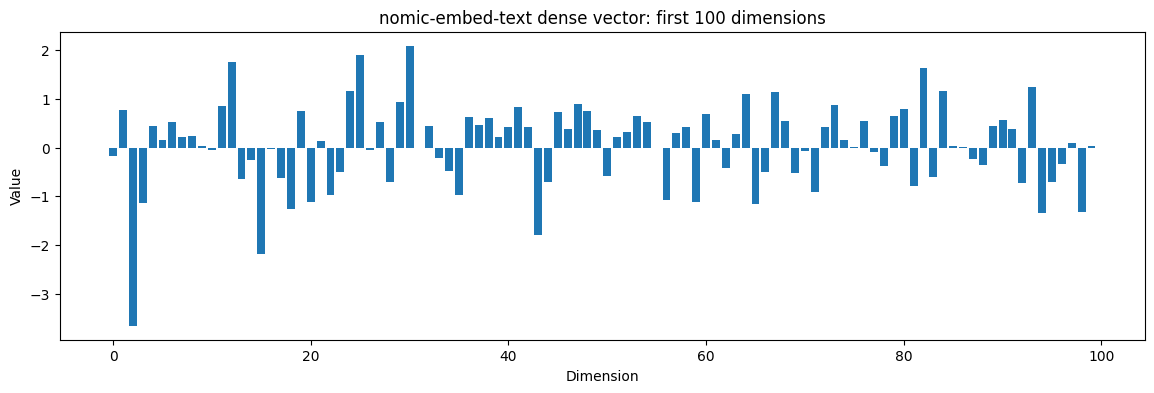

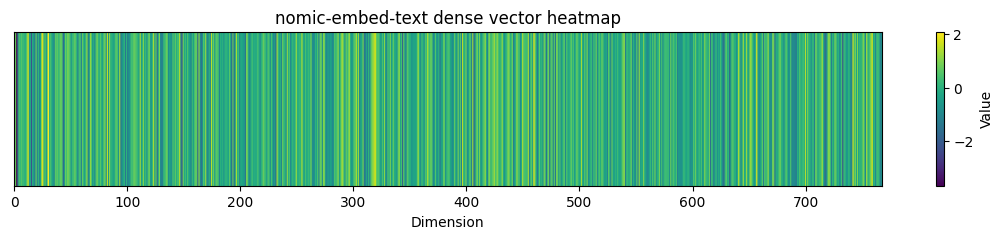

In [25]:
import requests
import numpy as np
import matplotlib.pyplot as plt

text = """A retrospective analysis was conducted on 332 adult patients who were diagnosed with AMI-CS and admitted to the ICU for the first time within the eICU Collaborative Research Database (eICU-CRD)."""

response = requests.post(
    "http://localhost:11434/api/embeddings",
    json={
        "model": "nomic-embed-text:latest",
        "prompt": text,
    },
)

response.raise_for_status()

vec = np.array(response.json()["embedding"])

print("=== Dense vector ===")
print("Model: nomic-embed-text:latest")
print("Vector shape:", vec.shape)
print("Number of dimensions:", len(vec))
print("First 20 values:")
print(vec[:20])

print("\n=== Dense vector stats ===")
print("Min:", vec.min())
print("Max:", vec.max())
print("Mean:", vec.mean())
print("Non-zero values:", np.count_nonzero(vec))
print("Zero values:", len(vec) - np.count_nonzero(vec))

# Plot first 100 dimensions
n = 100

plt.figure(figsize=(14, 4))
plt.bar(range(n), vec[:n])
plt.title(f"nomic-embed-text dense vector: first {n} dimensions")
plt.xlabel("Dimension")
plt.ylabel("Value")
plt.show()

# Heatmap-like visualization
plt.figure(figsize=(14, 2))
plt.imshow(vec.reshape(1, -1), aspect="auto")
plt.title("nomic-embed-text dense vector heatmap")
plt.xlabel("Dimension")
plt.yticks([])
plt.colorbar(label="Value")
plt.show()